# Week 1 — Rule-Based Routing Baseline
**Project:** AI Customer Support & Ticket Management Agent (Helix Agent) · **Intern:** Rajeshwari R · **KGIT**

This notebook builds a simple **keyword/rule-based** triage system and measures how well it predicts:
1. **Category** → which team gets the ticket
2. **Priority** (Low / Medium / High / Critical)
3. **Escalation** (needs a Team Lead or not)

These numbers are the **baseline**. From Week 2 onwards, the ML classifier must beat them.

Data: `data/kgit/tickets.csv` — 50 **synthetic** labeled KGIT helpdesk tickets (10 per category). Categories are **assumed** until the mentor confirms them.

In [1]:
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score)

df = pd.read_csv("../data/kgit/tickets.csv")
df["text"] = (df["subject"] + ". " + df["body"]).str.lower()
print(df.shape)
df[["ticket_id", "subject", "category", "priority", "assigned_team", "needs_escalation"]].head()

(50, 11)


,ticket_id,subject,category,priority,assigned_team,needs_escalation
0,TCK-0001,VPN down for whole team,IT Support,Critical,IT Service Desk,Yes
1,TCK-0002,Laptop very slow,IT Support,Medium,IT Service Desk,No
2,TCK-0003,Outlook not syncing,IT Support,Medium,IT Service Desk,No
3,TCK-0004,Install VS Code and Python,IT Support,Low,IT Service Desk,No
4,TCK-0005,Printer not working,IT Support,Low,IT Service Desk,No


## 1. Label distribution

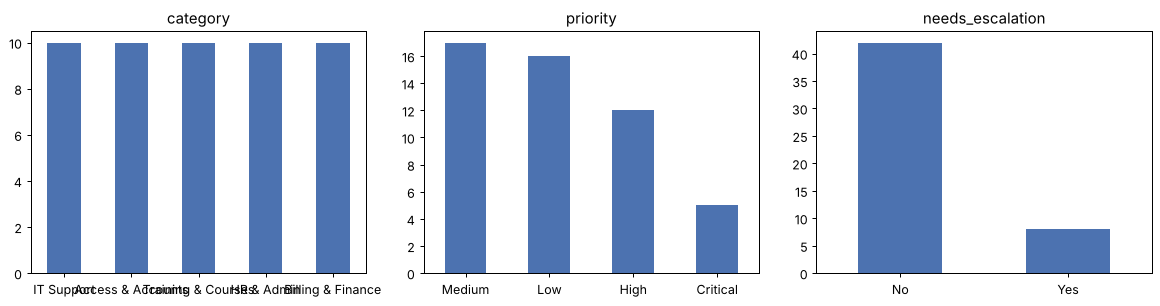

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["category", "priority", "needs_escalation"]):
    df[col].value_counts().plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 2. Routing rules
**Category:** count keyword hits per category; the category with the most hits wins. Ties → first in list. No hits → `General`.

**Priority:** checked from most to least severe (Critical → High → Medium); default `Low`.

**Escalation:** security/fraud/phishing, legal notice, harassment, data deletion, Critical priority, or complaint keywords.

In [3]:
CATEGORY_KEYWORDS = {
    "IT Support":         ["laptop", "vpn", "wi-fi", "wifi", "printer", "outlook", "email server", "install",
                           "software", "monitor", "blue screen", "network", "internet", "shared drive", "phishing",
                           "suspicious", "infected", "crash"],
    "Access & Accounts":  ["password", "login", "log in", "locked", "access", "github", "jira", "mfa",
                           "authenticator", "account", "new joiner", "joins", "remove his access", "permission"],
    "Training & Courses": ["course", "lms", "module", "certificate", "batch", "exam", "assessment", "trainer",
                           "session", "slides", "marks", "enroll", "recording", "class", "students"],
    "HR & Admin":         ["salary", "leave", "experience letter", "id card", "payslip", "hr portal", "harassment",
                           "colleague", "reimbursement", "holiday", "ac ", "bank details", "office"],
    "Billing & Finance":  ["fee", "charged", "receipt", "payment", "refund", "invoice", "emi", "billing",
                           "vendor", "deducted", "gst", "card", "legal notice"],
}
TEAM = {"IT Support": "IT Service Desk", "Access & Accounts": "Identity & Access Team",
        "Training & Courses": "Learning Team", "HR & Admin": "HR & Admin Team",
        "Billing & Finance": "Finance Team"}

PRIORITY_RULES = [
    ("Critical", ["fraud", "do not recognise", "did not do this", "phishing", "legal notice",
                  "entire team", "nobody can", "for all", "is down"]),
    ("High",     ["charged twice", "deducted", "salary has not", "cannot work", "cannot continue",
                  "cannot log in", "cannot get", "blue screen", "lost my phone", "remove his access",
                  "harassment", "delete my account", "whole batch", "exam starts"]),
    ("Medium",   ["slow", "not syncing", "disconnecting", "not loading", "buffering", "not received",
                  "locked", "pending", "error", "wrong", "missing", "refund", "rude", "new intern"]),
]

ESCALATION_KEYWORDS = ["fraud", "do not recognise", "did not do this", "phishing", "legal notice",
                       "harassment", "delete my account", "personal data", "rude", "insulted",
                       "unacceptable", "entire team", "nobody can"]

def predict_category(text):
    scores = {c: sum(kw in text for kw in kws) for c, kws in CATEGORY_KEYWORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "IT Support"

def predict_priority(text):
    for level, kws in PRIORITY_RULES:
        if any(kw in text for kw in kws):
            return level
    return "Low"

def predict_escalation(text, priority):
    return "Yes" if priority == "Critical" or any(kw in text for kw in ESCALATION_KEYWORDS) else "No"

df["pred_category"] = df["text"].apply(predict_category)
df["pred_team"] = df["pred_category"].map(TEAM)
df["pred_priority"] = df["text"].apply(predict_priority)
df["pred_escalation"] = [predict_escalation(t, p) for t, p in zip(df["text"], df["pred_priority"])]
df[["ticket_id", "subject", "category", "pred_category", "priority", "pred_priority",
    "needs_escalation", "pred_escalation"]].head(10)

## 3. Metrics
We compare the rules against a **majority-class baseline** (always predict the most common label).
Macro-F1 treats every class equally, so it is the main metric.

In [4]:
def majority(series):
    return [series.mode()[0]] * len(series)

rows = []
for task, y_true, y_pred in [
    ("Category / team", df["category"], df["pred_category"]),
    ("Priority",        df["priority"], df["pred_priority"]),
    ("Escalation",      df["needs_escalation"], df["pred_escalation"]),
]:
    rows.append({"task": task, "method": "Majority class",
                 "accuracy": accuracy_score(y_true, majority(y_true)),
                 "macro_f1": f1_score(y_true, majority(y_true), average="macro", zero_division=0)})
    rows.append({"task": task, "method": "Rule-based",
                 "accuracy": accuracy_score(y_true, y_pred),
                 "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)})
metrics = pd.DataFrame(rows).round(3)
metrics

,task,method,accuracy,macro_f1
0,Category / team,Majority class,0.20,0.067
1,Category / team,Rule-based,0.98,0.980
2,Priority,Majority class,0.34,0.127
3,Priority,Rule-based,0.98,0.985
4,Escalation,Majority class,0.84,0.457
5,Escalation,Rule-based,1.00,1.000


In [5]:
print("CATEGORY\n", classification_report(df["category"], df["pred_category"], zero_division=0))
print("PRIORITY\n", classification_report(df["priority"], df["pred_priority"],
      labels=["Critical", "High", "Medium", "Low"], zero_division=0))

esc_recall = recall_score(df["needs_escalation"], df["pred_escalation"], pos_label="Yes")
esc_precision = precision_score(df["needs_escalation"], df["pred_escalation"], pos_label="Yes")
print(f"ESCALATION  recall={esc_recall:.2f}  precision={esc_precision:.2f}")
print("Escalation recall matters most: a missed escalation is a safety risk.")

CATEGORY
                     precision    recall  f1-score   support

 Access & Accounts       1.00      1.00      1.00        10
 Billing & Finance       1.00      0.90      0.95        10
        HR & Admin       1.00      1.00      1.00        10
        IT Support       1.00      1.00      1.00        10
Training & Courses       0.91      1.00      0.95        10

          accuracy                           0.98        50
         macro avg       0.98      0.98      0.98        50
      weighted avg       0.98      0.98      0.98        50

PRIORITY
               precision    recall  f1-score   support

    Critical       1.00      1.00      1.00         5
        High       1.00      1.00      1.00        12
      Medium       1.00      0.94      0.97        17
         Low       0.94      1.00      0.97        16

    accuracy                           0.98        50
   macro avg       0.99      0.99      0.98        50
weighted avg       0.98      0.98      0.98        50

ES

## 4. Confusion matrices

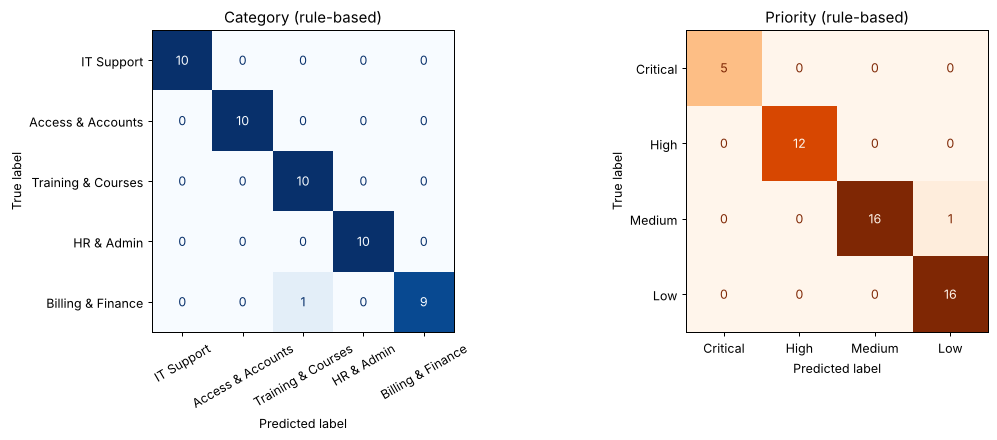

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cats = list(CATEGORY_KEYWORDS)
ConfusionMatrixDisplay(confusion_matrix(df["category"], df["pred_category"], labels=cats),
                       display_labels=cats).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Category (rule-based)"); axes[0].tick_params(axis="x", rotation=30)
pris = ["Critical", "High", "Medium", "Low"]
ConfusionMatrixDisplay(confusion_matrix(df["priority"], df["pred_priority"], labels=pris),
                       display_labels=pris).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Priority (rule-based)")
plt.tight_layout(); plt.savefig("../docs/kgit/baseline_confusion_matrix.png", dpi=120); plt.show()

## 4b. Fair check — rules on tickets they were NOT written from
The keywords above were written while looking at these 50 tickets, so the scores above are **optimistic**.
Below, the same rules are run on the **450 template training tickets** (`data/kgit/train_tickets.csv`), which use different wording.

In [7]:
train = pd.read_csv("../data/kgit/train_tickets.csv")
train["pred"] = train["text"].str.lower().apply(predict_category)
unseen_acc = accuracy_score(train["category"], train["pred"])
unseen_f1 = f1_score(train["category"], train["pred"], average="macro")
print(f"Rules on 450 unseen-wording tickets: accuracy {unseen_acc:.2f}, macro-F1 {unseen_f1:.2f}")

Rules on 450 unseen-wording tickets: accuracy 0.69, macro-F1 0.69


## 5. Error analysis — where do the rules fail?

In [8]:
errors = df[(df["category"] != df["pred_category"]) | (df["priority"] != df["pred_priority"])]
print(f"{len(errors)} of {len(df)} tickets have at least one wrong prediction\n")
errors[["ticket_id", "subject", "category", "pred_category", "priority", "pred_priority"]]

2 of 50 tickets have at least one wrong prediction



,ticket_id,subject,category,pred_category,priority,pred_priority
10,TCK-0011,Forgot LMS password,Access & Accounts,Access & Accounts,Medium,Low
43,TCK-0044,Refund for cancelled course,Billing & Finance,Training & Courses,Medium,Medium


**Typical failure reasons**
- **Shared words across categories** — e.g. *"access"* and *"account"* appear in IT, Access and Billing tickets; *"card"* can be an ID card (HR) or a payment card (Billing).
- **Priority depends on meaning, not words** — "I cannot log in" can be Medium or High depending on impact; keywords cannot see context.
- **Rules do not generalise** — new phrasing (e.g. "money got cut twice") is missed unless a keyword is added by hand.

These limitations are the reason for the Week 2 **ML classifier** and the Week 3 **RAG + guardrails**.

## 6. Save baseline results

In [9]:
df[["ticket_id", "category", "pred_category", "pred_team", "priority", "pred_priority",
    "needs_escalation", "pred_escalation"]].to_csv("../data/kgit/baseline_predictions.csv", index=False)

summary = {
    "dataset": "data/kgit/tickets.csv (50 synthetic KGIT tickets)",
    "method": "keyword rule-based routing",
    "results": metrics.to_dict(orient="records"),
    "escalation_recall": round(esc_recall, 3),
    "escalation_precision": round(esc_precision, 3),
    "rules_on_unseen_wording_accuracy": round(unseen_acc, 3),
    "rules_on_unseen_wording_macro_f1": round(unseen_f1, 3),
}
with open("../docs/kgit/baseline_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset": "data/kgit/tickets.csv (50 synthetic KGIT tickets)",
  "method": "keyword rule-based routing",
  "results": [
    {
      "task": "Category / team",
      "method": "Majority class",
      "accuracy": 0.2,
      "macro_f1": 0.067
    },
    {
      "task": "Category / team",
      "method": "Rule-based",
      "accuracy": 0.98,
      "macro_f1": 0.98
    },
    {
      "task": "Priority",
      "method": "Majority class",
      "accuracy": 0.34,
      "macro_f1": 0.127
    },
    {
      "task": "Priority",
      "method": "Rule-based",
      "accuracy": 0.98,
      "macro_f1": 0.985
    },
    {
      "task": "Escalation",
      "method": "Majority class",
      "accuracy": 0.84,
      "macro_f1": 0.457
    },
    {
      "task": "Escalation",
      "method": "Rule-based",
      "accuracy": 1.0,
      "macro_f1": 1.0
    }
  ],
  "escalation_recall": 1.0,
  "escalation_precision": 1.0,
  "rules_on_unseen_wording_accuracy": 0.689,
  "rules_on_unseen_wording_macro_f1": 0.

## 7. Conclusion
- The rule-based router gives a **measurable baseline** for category, priority and escalation.
- It is better than the majority-class baseline but **brittle**: on the 50 tickets the keywords were written from it looks excellent, but on 450 tickets with **different wording** its accuracy drops sharply (section 4b).
- **Next (Week 2):** train an ML classifier (TF-IDF + Logistic Regression) on a train/test split and compare against these numbers using the same metrics and confusion matrix.